# MC2 · Pattern Detection · Day 6 – Technical Implementation
**Algorithm: Hough circle transform**, including the edge detection that provides its input.

*Scope: step-wise implementation, intermediate results, and verification on a synthetic test image. No use case, parameter tuning or evaluation (Days 7–10).*

Circular patterns are frequent in Japanese images (festival crests, flags, lantern openings, manhole covers); the transform consists of clearly separable steps with an informative intermediate result, the accumulator.

## 1. Algorithm
A circle with centre $(a,b)$ and radius $r$ satisfies $(x-a)^2+(y-b)^2=r^2$. The Hough transform maps edge pixels to this parameter space: an edge pixel $(x,y)$ is consistent with all circles of radius $r$ whose centre lies at distance $r$ from it, i.e. on a circle around $(x,y)$ in the $(a,b)$ plane. Each edge pixel adds one vote to every such cell of an accumulator $A[r,b,a]$. The cell of a true circle collects the votes of all its edge pixels; local maxima of $A$ are the detected circles.

| # | Step | Operation | Parameter |
|---|---|---|---|
| 1 | smoothing | Gaussian filter, noise suppression before differentiation | $\sigma$ |
| 2 | gradient | Sobel operator: $G_x$, $G_y$, $\lvert G\rvert$, direction $\theta$ | – |
| 3 | thinning | non-maximum suppression along $\theta$ | – |
| 4 | edge map | threshold on the thinned magnitude | `EDGE_FRAC` |
| 5 | voting, peaks | accumulator over $(r,y,x)$, local maxima, minimum separation | `RADII`, `PEAK_THR`, `MIN_SEP` |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi

# ---------------- parameters (all in one place, nothing is tuned on this day) ----------------
SIGMA      = 1.5               # Gaussian blur [px]
EDGE_FRAC  = 0.20              # edge threshold as a fraction of the maximum thinned gradient magnitude
RADII      = np.arange(12, 61) # radii searched [px]
PEAK_THR   = 0.60              # minimum normalised accumulator value for a circle (see step 5)
MIN_SEP    = 10                # minimum distance between two detected circles in (x, y, r) [px]
print(f"sigma={SIGMA}px | edge threshold={EDGE_FRAC} x max | radii {RADII.min()}..{RADII.max()} px | peak threshold={PEAK_THR} | min separation={MIN_SEP}px")

sigma=1.5px | edge threshold=0.2 x max | radii 12..60 px | peak threshold=0.6 | min separation=10px


## 2. Test image
Synthetic image (240 × 240 px) with known content: three dark discs (radii 18, 28, 45 px) on a bright background, a rectangle as non-circular distractor, and Gaussian noise ($\sigma=4$ grey levels). Ground truth $(x,y,r,\text{value})$ is stored in `truth`.

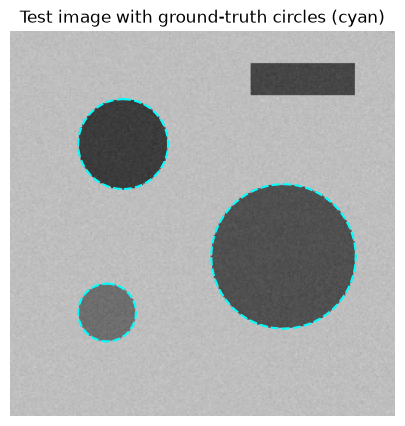

In [2]:
def make_test_image(seed=0):
    H = W = 240
    yy, xx = np.mgrid[0:H, 0:W]
    img = np.full((H, W), 190.0)
    truth = [(70, 70, 28, 60), (170, 140, 45, 80), (60, 175, 18, 110)]   # (cx, cy, r, grey value)
    for cx, cy, r, v in truth:
        img[(xx - cx) ** 2 + (yy - cy) ** 2 <= r ** 2] = v
    img[20:40, 150:215] = 70                                            # non-circular distractor
    img += np.random.default_rng(seed).normal(0, 4, img.shape)          # sensor-like noise
    return np.clip(img, 0, 255), truth

test, truth = make_test_image()
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(test, cmap="gray", vmin=0, vmax=255)
for cx, cy, r, _ in truth:
    ax.add_patch(plt.Circle((cx, cy), r, fill=False, ec="cyan", ls="--", lw=1.5))
ax.set_title("Test image with ground-truth circles (cyan)"); ax.axis("off")
plt.show()

**Figure A1.** Test image (input of the algorithm) with the ground-truth circles (cyan, dashed). The ground truth is shown for verification only and is not used by the algorithm. The three radii test the radius search; the rectangle tests the rejection of straight edges.

## 3. Implementation
**Step 1 – Smoothing.** A Gaussian filter of width $\sigma$ reduces noise, which differentiation would amplify.

**Step 2 – Sobel gradient.**
$$K_x=\begin{pmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{pmatrix},\quad K_y=K_x^{T},\qquad \lvert G\rvert=\sqrt{G_x^2+G_y^2},\quad \theta=\operatorname{atan2}(G_y,G_x)$$
$\lvert G\rvert$ is large at intensity transitions; $\theta$ points across the edge.

**Step 3 – Non-maximum suppression.** $\lvert G\rvert$ is kept at a pixel only if it is maximal compared with its two neighbours along $\theta$ (quantised to 0°, 45°, 90°, 135°). The result is an edge of about one pixel width, which limits the number of votes per edge.

**Step 4 – Edge map.** Pixels with thinned magnitude $\ge$ `EDGE_FRAC` $\cdot \max$ form the binary edge map.

In [3]:
def smooth(img, sigma):
    return ndi.gaussian_filter(img, sigma, mode="reflect")                       # step 1

def sobel(img):
    kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)            # step 2
    gx = ndi.correlate(img, kx, mode="reflect")
    gy = ndi.correlate(img, kx.T, mode="reflect")
    return gx, gy, np.hypot(gx, gy), np.arctan2(gy, gx)

def non_max_suppression(mag, ang):
    a = np.rad2deg(ang) % 180                                                    # step 3
    q = np.select([a < 22.5, a < 67.5, a < 112.5, a < 157.5], [0, 1, 2, 3], 0)  # direction class
    shifts = {0: (0, 1), 1: (1, 1), 2: (1, 0), 3: (1, -1)}                       # (dy, dx) along the gradient
    out = np.zeros_like(mag)
    for k, (dy, dx) in shifts.items():
        n1 = np.roll(mag, (-dy, -dx), axis=(0, 1))
        n2 = np.roll(mag, (dy, dx), axis=(0, 1))
        keep = (q == k) & (mag > n1) & (mag >= n2)
        out[keep] = mag[keep]
    out[0, :] = out[-1, :] = 0; out[:, 0] = out[:, -1] = 0                       # remove wrap-around at the border
    return out

def edge_map(nms, frac):
    return nms >= frac * nms.max()                                               # step 4

blurred            = smooth(test, SIGMA)
gx, gy, mag, ang   = sobel(blurred)
nms                = non_max_suppression(mag, ang)
edges              = edge_map(nms, EDGE_FRAC)
print(f"edge pixels: {int(edges.sum())} of {edges.size} ({100 * edges.mean():.1f} %)")

edge pixels: 838 of 57600 (1.5 %)


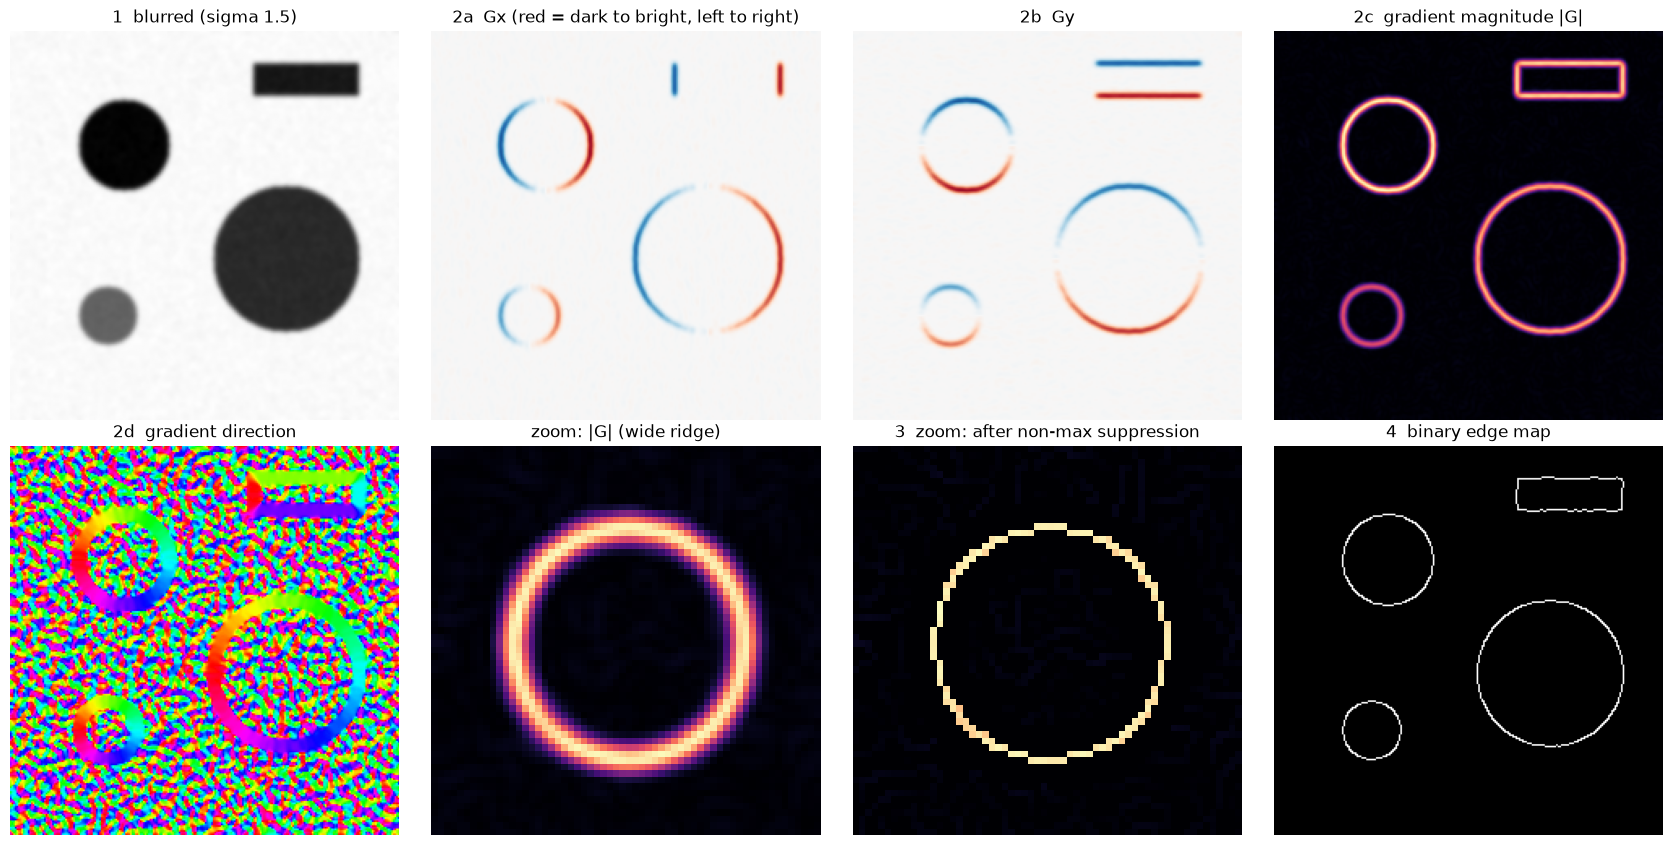

In [4]:
zx, zy = slice(145, 205), slice(30, 90)       # zoom on the smallest disc
fig, axs = plt.subplots(2, 4, figsize=(17, 8.5))
axs[0, 0].imshow(blurred, cmap="gray");                  axs[0, 0].set_title("1  blurred (sigma 1.5)")
axs[0, 1].imshow(gx, cmap="RdBu_r", vmin=-300, vmax=300); axs[0, 1].set_title("2a  Gx (red = dark to bright, left to right)")
axs[0, 2].imshow(gy, cmap="RdBu_r", vmin=-300, vmax=300); axs[0, 2].set_title("2b  Gy")
axs[0, 3].imshow(mag, cmap="magma");                     axs[0, 3].set_title("2c  gradient magnitude |G|")
axs[1, 0].imshow(ang, cmap="hsv", vmin=-np.pi, vmax=np.pi); axs[1, 0].set_title("2d  gradient direction")
axs[1, 1].imshow(mag[zx, zy], cmap="magma", interpolation="nearest"); axs[1, 1].set_title("zoom: |G| (wide ridge)")
axs[1, 2].imshow(nms[zx, zy], cmap="magma", interpolation="nearest"); axs[1, 2].set_title("3  zoom: after non-max suppression")
axs[1, 3].imshow(edges, cmap="gray");                    axs[1, 3].set_title("4  binary edge map")
for a in axs.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

**Figure A2.** Edge detection steps. *1:* smoothed image. *2a, 2b:* Sobel derivatives $G_x$, $G_y$ (red positive, blue negative); $G_x$ responds to vertical, $G_y$ to horizontal edges, with opposite sign on opposite sides of a disc. *2c:* gradient magnitude; all outlines, including the rectangle, form ridges. *2d:* gradient direction; around each disc the angle runs through the full circle because the gradient is directed along the radius. *Zoom, |G| vs. NMS:* the ridge of several pixels width is reduced to a thin line. *4:* binary edge map, the input of the Hough transform.

**Step 5 – Voting and peak detection.** For each radius $r\in$ `RADII` and each edge pixel $(x,y)$, one vote is added to the cells $(a,b)=(x+r\cos t,\;y+r\sin t)$ for $n_r=\lceil 2\pi r\rceil$ angles $t$ (about one sample per circumference pixel). The accumulator has one 2-D layer per radius.

*Normalisation.* Layer $r$ is divided by $n_r$, so that the value approximates the fraction of the circumference covered by edge pixels (≈ 1 for a complete circle) and `PEAK_THR` is comparable across radii.

*Peaks.* Local maxima in a $5\times5\times5$ neighbourhood with value $\ge$ `PEAK_THR` are sorted by value; a peak is accepted if its distance in $(a,b,r)$ to all accepted peaks is $\ge$ `MIN_SEP`.

In [5]:
def hough_circle_accumulator(edge, radii):
    H, W = edge.shape
    ys, xs = np.nonzero(edge)
    acc = np.zeros((len(radii), H, W), dtype=np.float32)
    for i, r in enumerate(radii):
        n = int(np.ceil(2 * np.pi * r))
        t = np.linspace(0, 2 * np.pi, n, endpoint=False)
        cy = np.rint(ys[:, None] + r * np.sin(t)[None, :]).astype(int).ravel()    # candidate centres of all edge pixels
        cx = np.rint(xs[:, None] + r * np.cos(t)[None, :]).astype(int).ravel()
        ok = (cy >= 0) & (cy < H) & (cx >= 0) & (cx < W)
        votes = np.bincount(cy[ok] * W + cx[ok], minlength=H * W)                   # voting
        acc[i] = votes.reshape(H, W) / n                                            # normalise by circumference
    return acc

def find_circles(acc, radii, thr, min_sep):
    local_max = acc == ndi.maximum_filter(acc, size=(5, 5, 5), mode="constant")
    idx = np.argwhere(local_max & (acc >= thr))
    order = np.argsort(-acc[tuple(idx.T)])
    found = []
    for ri, cy, cx in idx[order]:
        c = (cx, cy, radii[ri])
        if all(np.linalg.norm(np.subtract(c, f[:3])) >= min_sep for f in found):
            found.append((int(cx), int(cy), int(radii[ri]), float(acc[ri, cy, cx])))
    return found

acc = hough_circle_accumulator(edges, RADII)
circles = find_circles(acc, RADII, PEAK_THR, MIN_SEP)
print("accumulator shape (radii, y, x):", acc.shape, "| maximum value:", round(float(acc.max()), 2))
print("detected circles (x, y, r, accumulator value):")
for c in circles: print("  ", c[:3], round(c[3], 2))

accumulator shape (radii, y, x): (49, 240, 240) | maximum value: 0.95
detected circles (x, y, r, accumulator value):
   (170, 140, 45) 0.95
   (70, 70, 28) 0.9
   (60, 175, 18) 0.85


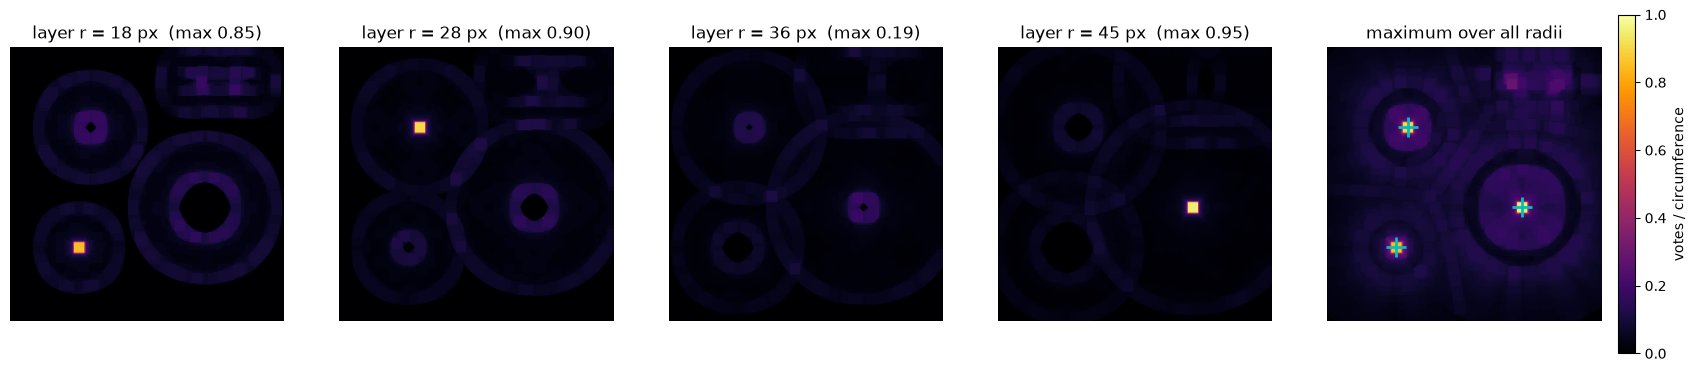

In [6]:
show_r = [18, 28, 36, 45]                                   # three true radii and one radius without a circle
fig, axs = plt.subplots(1, 5, figsize=(21, 4.4))
for a, r in zip(axs[:4], show_r):
    layer = acc[list(RADII).index(r)]
    m = a.imshow(ndi.maximum_filter(layer, size=9), cmap="inferno", vmin=0, vmax=1.0)   # 9x9 max filter for display only
    a.set_title(f"layer r = {r} px  (max {layer.max():.2f})"); a.axis("off")
axs[4].imshow(ndi.maximum_filter(acc.max(axis=0), size=9), cmap="inferno", vmin=0, vmax=1.0); axs[4].set_title("maximum over all radii"); axs[4].axis("off")
for cx, cy, r, _ in circles:
    axs[4].plot(cx, cy, "c+", ms=14, mew=2)
fig.colorbar(m, ax=axs, fraction=0.012, pad=0.01, label="votes / circumference")
plt.show()

**Figure A3.** Accumulator layers for $r=18, 28, 36, 45$ px and the maximum over all radii. Brightness is the normalised vote count; the number in each title is the layer maximum. Layers are drawn with a $9\times9$ maximum filter for visibility only (data unchanged). The layers $r=18, 28, 45$ each contain one peak at the centre of the disc of that radius (maxima 0.85, 0.90, 0.95); other discs contribute only weak ring-shaped structures. For $r=36$, no disc exists and the layer maximum is 0.19. In the maximum projection, each disc yields one peak at its centre (cyan crosses: accepted peaks).

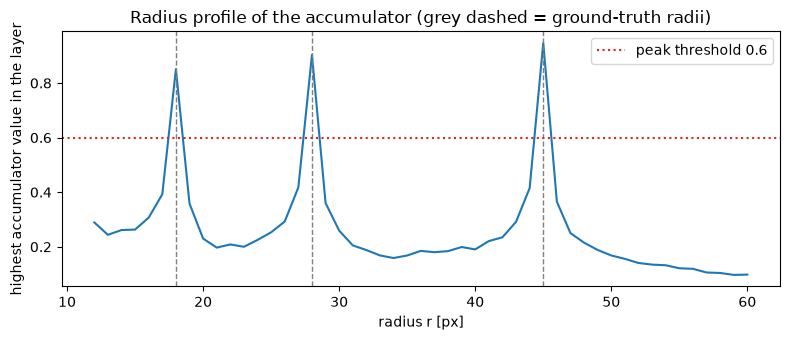

In [7]:
prof = acc.reshape(len(RADII), -1).max(axis=1)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(RADII, prof, color="tab:blue")
for _, _, r, _ in truth: ax.axvline(r, color="gray", ls="--", lw=1)
ax.axhline(PEAK_THR, color="tab:red", ls=":", label=f"peak threshold {PEAK_THR}")
ax.set_xlabel("radius r [px]"); ax.set_ylabel("highest accumulator value in the layer")
ax.set_title("Radius profile of the accumulator (grey dashed = ground-truth radii)"); ax.legend()
plt.tight_layout(); plt.show()

**Figure A4.** Maximum accumulator value per radius. Maxima occur at the radii of the three discs (grey dashed lines); between them the curve remains low. Only maxima above `PEAK_THR` (red dotted) can become detections. This is the radius axis of the accumulator, which the 2-D layers do not show.

## 4. Verification
The detections are compared with the ground truth of the test image (functional check of the implementation, not an evaluation of the method).

truth (x, y, r)     detected (x, y, r)    error dx, dy, dr    
(70, 70, 28)        (70, 70, 28)          (0, 0, 0)           
(170, 140, 45)      (170, 140, 45)        (0, 0, 0)           
(60, 175, 18)       (60, 175, 18)         (0, 0, 0)           

number of detections: 3 (ground truth: 3) | largest error: 0 px


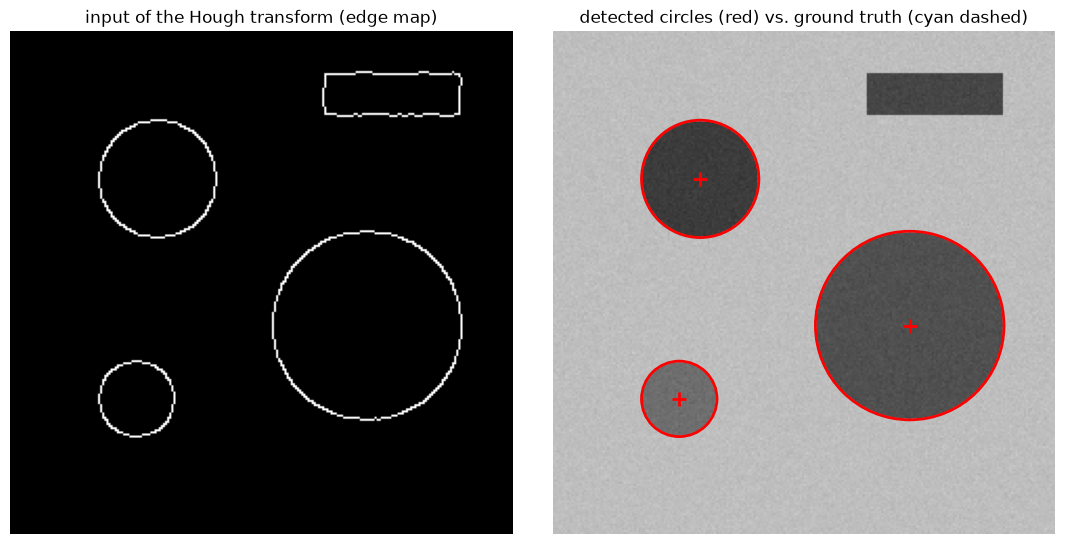

In [8]:
print(f"{'truth (x, y, r)':<20}{'detected (x, y, r)':<22}{'error dx, dy, dr':<20}")
errs = []
for cx, cy, r, _ in truth:
    d = min(circles, key=lambda c: np.hypot(c[0] - cx, c[1] - cy) + abs(c[2] - r))
    e = (d[0] - cx, d[1] - cy, d[2] - r); errs.append(max(abs(v) for v in e))
    print(f"{str((cx, cy, r)):<20}{str(tuple(int(v) for v in d[:3])):<22}{str(tuple(int(v) for v in e)):<20}")
print(f"\nnumber of detections: {len(circles)} (ground truth: {len(truth)}) | largest error: {max(errs)} px")
assert len(circles) == len(truth) and max(errs) <= 2, "verification failed"

fig, axs = plt.subplots(1, 2, figsize=(11, 5.4))
axs[0].imshow(edges, cmap="gray"); axs[0].set_title("input of the Hough transform (edge map)")
axs[1].imshow(test, cmap="gray", vmin=0, vmax=255); axs[1].set_title("detected circles (red) vs. ground truth (cyan dashed)")
for cx, cy, r, _ in truth:  axs[1].add_patch(plt.Circle((cx, cy), r, fill=False, ec="cyan", ls="--", lw=1.5))
for cx, cy, r, _ in circles:
    axs[1].add_patch(plt.Circle((cx, cy), r, fill=False, ec="red", lw=2)); axs[1].plot(cx, cy, "r+", ms=10, mew=2)
for a in axs: a.axis("off")
plt.tight_layout(); plt.show()

**Figure A5.** Left: edge map used as input. Right: detected circles (red) and ground truth (cyan, dashed) on the test image. The table above lists the deviation of centre and radius for each circle; the assertion terminates the notebook if the number of detections differs from the ground truth or the deviation exceeds 2 px. The rectangle produces no detection, since its straight edges do not vote consistently for a single centre.

---
# Day 7 · Data & Domain

## 1. Use case and problem statement
**Use case.** Each lantern of the kanto towers at the Akita Kanto Festival (Akita, Japan) carries one red circular crest (emblem of Akita City). Automatic cataloguing of festival photographs requires the number and positions of the lanterns of a tower. Since each lantern has exactly one crest, localising the crests yields the lantern count, the lantern grid and anchor points for cropping (e.g. for lettering recognition). The crest is more compact and more regular than the lantern, whose outline is occluded by bamboo bars and neighbouring lanterns.

**Problem.** In night photographs, crest localisation is impeded by
- numerous other curved edges (elliptical lantern outlines and openings),
- perspective: the crest size varies with height and its shape is slightly distorted,
- occlusion (bamboo bars, performers) and glow at the lantern rim,
- concentric inner structure: one crest yields several circular edges,
- low colour contrast (red on orange), which depends on the grey conversion.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

IMG_PATH = "akita-kanto-festival-by-annintofu-flickr-2187739691.jpg"
img = np.array(Image.open(IMG_PATH).convert("RGB"))
H, W, _ = img.shape
print(f"image: {W} x {H} px, {img.shape[2]} channels, {img.dtype}")

# Regions (x0, x1, y0, y1) in original pixel coordinates, defined visually (not detected)
TOWER = (1010, 1360, 480, 960)    # right-hand tower with red crests
CREST = (1190, 1275, 560, 640)    # one lantern with its crest

image: 2048 x 1366 px, 3 channels, uint8


## 2. Image
**Origin.** Photograph "Akita Kanto Festival" by *annintofu* (Flickr), obtained via the Bunnik Tours photo gallery. No licence is stated; the image is used for non-commercial coursework with attribution. It is the image used in the augmentation notebook.

**Content.** Night scene, low viewpoint, 2048 × 1366 px, RGB. Two lantern towers in the centre (left: black lettering; right: red crests), two tilted towers in the background, performers in the foreground, black sky.

**Visual characteristics.**
- *Crests:* dark red emblems on bright orange paper, one per lantern, in a regular grid; size varies slowly with height and distance.
- *Circular structure:* roughly circular outer boundary with concentric inner rings and a central dot; the lanterns themselves are ellipses.
- *Straight structure:* bamboo crossbars and the pole.
- *Intensity:* self-lit, smooth paper on a black background; lantern outlines have strong edges, crests weaker ones.
- *Noise:* sensor noise and JPEG blocks in dark regions.

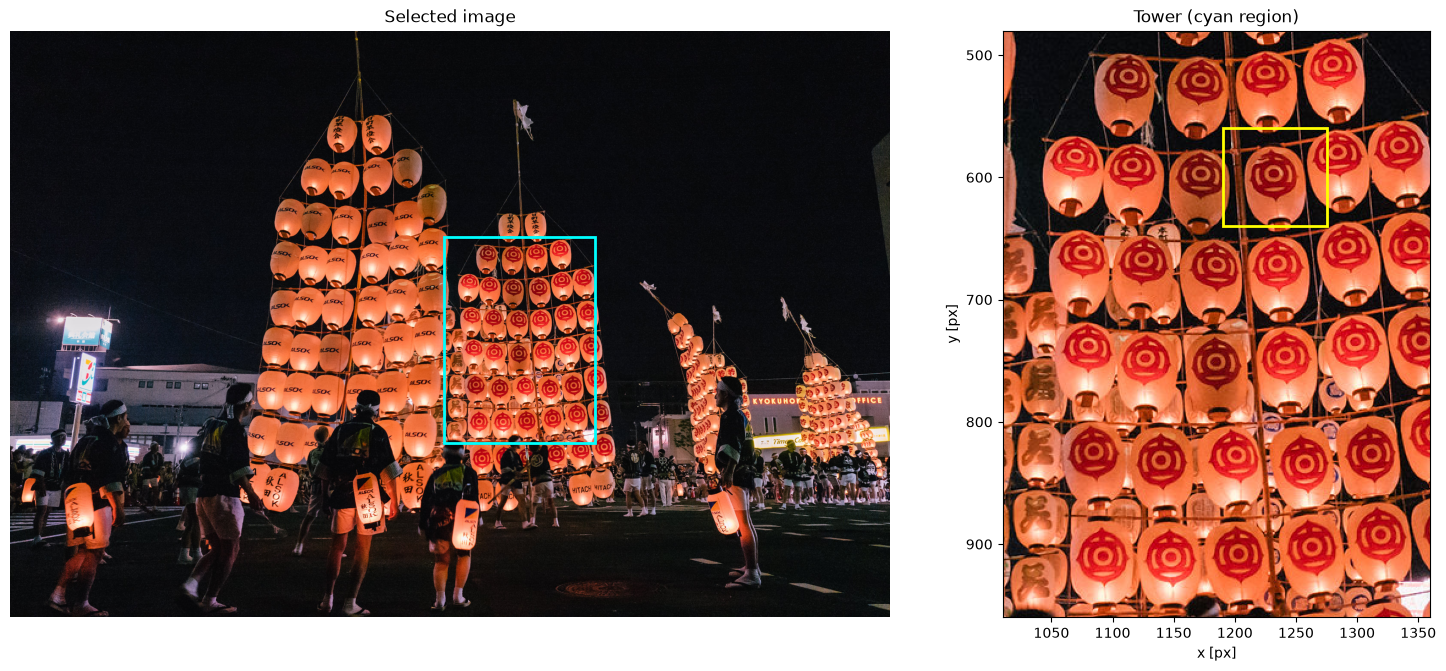

In [10]:
x0, x1, y0, y1 = TOWER
a, b, c, d = CREST
fig, axs = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [2.2, 1]})
axs[0].imshow(img)
axs[0].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="cyan", lw=2))
axs[0].set_title("Selected image"); axs[0].axis("off")
axs[1].imshow(img[y0:y1, x0:x1], extent=(x0, x1, y1, y0))
axs[1].add_patch(plt.Rectangle((a, c), b - a, d - c, fill=False, ec="yellow", lw=2))
axs[1].set_title("Tower (cyan region)"); axs[1].set_xlabel("x [px]"); axs[1].set_ylabel("y [px]")
plt.tight_layout(); plt.show()

**Figure 1.** Left: the image with the tower region (cyan). Right: the tower at original resolution with pixel coordinates; the crests form a regular grid of about eight rows with four to five crests each, crests in lower rows appear larger, and the yellow rectangle marks the crest analysed below. Some lanterns at the left edge carry lettering instead of a crest. Regions were chosen visually and are not algorithm outputs.

## 3. Pattern of interest
**Structure.** The outer boundary of the red crest on the lantern in the yellow rectangle: a closed, approximately circular contour with strong colour contrast to the surrounding paper.

**Detection target.** The shape of this contour as a circle, i.e. centre $(x,y)$ and radius $r$; not the lantern outline and not the inner details.

**Appearance.** Visual estimate: centre ≈ (1232, 598), outer radius ≈ 19–20 px. Inside, concentric structures follow (Figure 3). The contour deviates from a circle by a small tip at the bottom and a bump at the top.

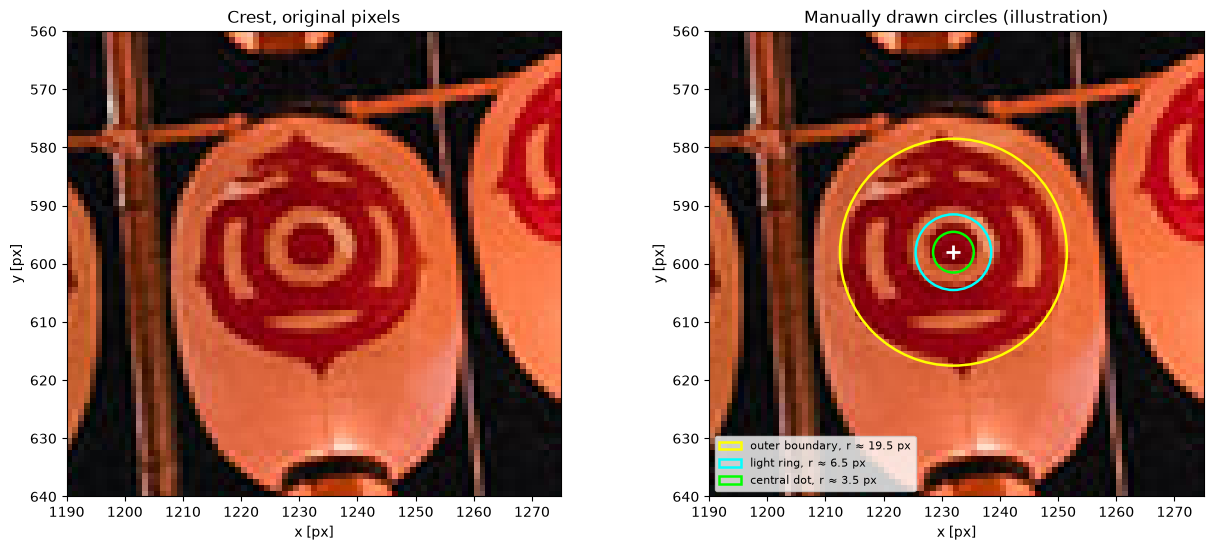

In [11]:
cx, cy = 1232, 598                                    # visually estimated crest centre
fig, axs = plt.subplots(1, 2, figsize=(13, 5.6))
for ax in axs:
    ax.imshow(img[c:d, a:b], extent=(a, b, d, c), interpolation="nearest")
    ax.set_xlabel("x [px]"); ax.set_ylabel("y [px]")
axs[0].set_title("Crest, original pixels")
for r, col, lab in [(19.5, "yellow", "outer boundary, r ≈ 19.5 px"), (6.5, "cyan", "light ring, r ≈ 6.5 px"), (3.5, "lime", "central dot, r ≈ 3.5 px")]:
    axs[1].add_patch(plt.Circle((cx, cy), r, fill=False, ec=col, lw=1.8, label=lab))
axs[1].plot(cx, cy, "w+", ms=10, mew=2); axs[1].legend(loc="lower left", fontsize=8)
axs[1].set_title("Manually drawn circles (illustration)")
plt.tight_layout(); plt.show()

**Figure 2.** Left: the crest at original pixel size without interpolation. Right: circles drawn manually from the radial profile of Figure 3 (outer boundary, light ring, central dot). They illustrate the concentric structure and the target size and are not the result of the Day 6 algorithm.

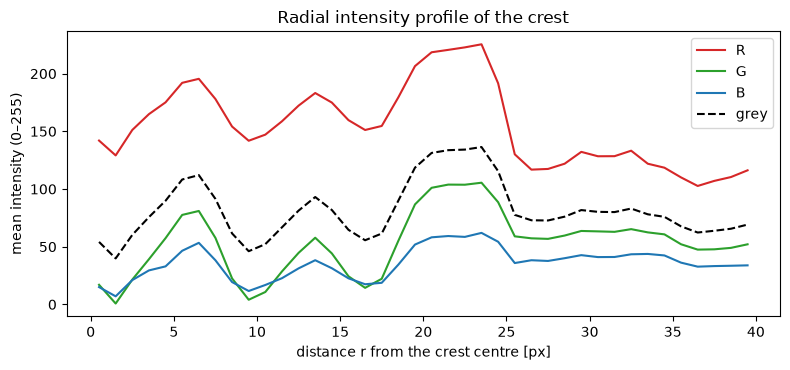

In [12]:
yy, xx = np.mgrid[c:d, a:b]
rad = np.hypot(xx - cx, yy - cy)
grey = 0.299 * img[c:d, a:b, 0] + 0.587 * img[c:d, a:b, 1] + 0.114 * img[c:d, a:b, 2]
r_axis = np.arange(0, 40)
fig, ax = plt.subplots(figsize=(8, 3.8))
for k, (n, col) in enumerate([("R", "tab:red"), ("G", "tab:green"), ("B", "tab:blue")]):
    ch = img[c:d, a:b, k].astype(float)
    ax.plot(r_axis + 0.5, [ch[(rad >= r) & (rad < r + 1)].mean() for r in r_axis], color=col, label=n)
ax.plot(r_axis + 0.5, [grey[(rad >= r) & (rad < r + 1)].mean() for r in r_axis], "k--", label="grey")
ax.set_xlabel("distance r from the crest centre [px]"); ax.set_ylabel("mean intensity (0–255)")
ax.set_title("Radial intensity profile of the crest"); ax.legend()
plt.tight_layout(); plt.show()

**Figure 3.** Mean channel intensity as a function of the distance $r$ from the crest centre. From the centre: dark dot (minimum at $r\approx1$–2 px), light ring (maximum at 6–7 px), dark ring (minimum at 9–10 px), light arcs (13–14 px), dark band (16–17 px), then a steep rise at $r\approx19$–20 px, which is the outer boundary, up to the paper plateau (to ≈ 24 px). Beyond ≈ 25 px the intensity falls at the lantern edge. All channels decrease inside the crest, with different relative contrast: red from ≈ 220 to ≈ 150 (≈ 30 %), green from ≈ 105 to ≈ 15 and blue from ≈ 60 to ≈ 15. The boundary contrast is thus lowest in the red channel and highest in green and blue; the grey image (green-weighted) lies in between.

## 4. Relevance, manifestation and objective
**Relevance.** One crest per lantern: crest count and positions give lantern count and grid; centre and radius provide a reference for cropping each lantern; the crest is the most compact, round and repeated structure of a lantern.

**Manifestation in the image.** Dozens of crests of varying size occur among elliptical lantern outlines and straight bars, with concentric inner edges, partial occlusion and glowing paper. Many edge pixels therefore do not belong to a crest boundary.

**Objective.** Localise the red crests as circles, returning centre and radius for each visible crest (shape-based boundary extraction), for counting and as anchors. The Hough circle transform of Day 6 operates on an edge map and accumulates evidence for $(x,y,r)$, which is the parametrisation of the target.